In [39]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from scipy.optimize import brentq
from scipy.interpolate import interp1d

In [2]:
import seaborn as sns

In [3]:
def print_expert_stats(name, idx, raw, scaled):
    print(f"{name} (idx={idx})")
    print("-" * 40)

    print("Raw logits")
    print(f"  std: {np.std(raw[idx]):.4f}")
    print(f"  min/max: {raw[idx].min():.4f} / {raw[idx].max():.4f}")

    print("\nScaled logits")
    print(f"  std: {np.std(scaled[idx]):.6f}")
    print(f"  min/max: {scaled[idx].min():.6f} / {scaled[idx].max():.6f}")

    print()


def plot_platt(a, b, logits, ax=None, title=""):
    if ax is None:
        ax = plt.gca()

    # Full sigmoid
    z_full = np.linspace(-10, 10, 1000)
    p_full = 1 / (1 + np.exp(-(a * z_full + b)))

    # Data range
    z_min, z_max = logits.min(), logits.max()
    z_data = np.linspace(z_min, z_max, 500)
    p_data = 1 / (1 + np.exp(-(a * z_data + b)))

    # Min/max points
    p_min = 1 / (1 + np.exp(-(a * z_min + b)))
    p_max = 1 / (1 + np.exp(-(a * z_max + b)))

    # Plot on given axis
    ax.plot(z_full, p_full, label="Full sigmoid", alpha=0.5)
    ax.plot(z_data, p_data, linewidth=3, label="Used region")
    ax.scatter([z_min, z_max], [p_min, p_max], color="red", zorder=3, label="min/max raw logits")
    ax.axvline(z_min, linestyle="--", alpha=0.5)
    ax.axvline(z_max, linestyle="--", alpha=0.5)
    ax.set_xlabel("logits (z)")
    ax.set_ylabel("probability")
    ax.set_title(title)
    #ax.legend()
    ax.grid()


In [43]:
def compute_cllr(scores, labels):
    scores = np.array(scores)
    labels = np.array(labels)
    tar = scores[labels == 1]
    non = scores[labels == 0]
    c1 = np.mean(np.log2(1 + np.exp(-tar)))
    c2 = np.mean(np.log2(1 + np.exp(non)))
    return (c1 + c2) / 2

def print_metrics(scores, labels):
    fpr, tpr, thres = roc_curve(labels, scores)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    eer_func = interp1d(fpr, fnr)
    eer = brentq(lambda x: eer_func(x) - x, 0., 1.)
    cllr = compute_cllr(scores, labels)
    
    preds = (scores >= 0).astype(int)
    
    bacc = balanced_accuracy_score(preds, labels)
    acc = accuracy_score(preds, labels)
    prec = precision_score(labels, preds)
    rec = recall_score(labels, preds)
    f1 = f1_score(labels, preds)

    header = f"{'AUC%':>8} {'EER%':>8} {'Cllr':>8} {'B.Acc.':>8} {'Acc.':>8} {'Prec.':>8} {'Recall':>8} {'F1':>8}"
    print(header)
    print(f"{rocauc*100:>8.2f} "
          f"{eer*100:>8.2f} "
          f"{cllr:>8.4f} "
          f"{bacc*100:>8.2f} "
          f"{acc*100:>8.2f} "
          f"{prec*100:>8.2f} "
          f"{rec*100:>8.2f} "
          f"{f1*100:>8.2f}")

def load_results(path):
    logLR_scores = np.load(os.path.join(path, "scores_per_expert.npy"))
    labels = np.load(os.path.join(path, "labels.npy"))
    attack_ids = np.load(os.path.join(path, "attack_ids.npy"))
    return logLR_scores, labels, attack_ids
    
def plot_distributions(real_scores, fake_scores, lbound=None, hbound=None, thr=0, ax=None, metrics=True):

    labels = np.concatenate([
        np.zeros(len(real_scores)),
        np.ones(len(fake_scores))
    ])
    
    if metrics:
        print_metrics(np.concatenate([real_scores, fake_scores]), labels)
        print()
        print(f"   Real mean score: {real_scores.mean():.4f}")
        print(f"   Fake mean score: {fake_scores.mean():.4f}\n")
        
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    sns.kdeplot(real_scores, fill=True, alpha=0.5, label="Real (0)", ax=ax)
    sns.kdeplot(fake_scores, fill=True, alpha=0.5, label="Fake (1)", ax=ax)
    #sns.histplot(real_scores, bins=50, stat="count", kde=False, color='blue', alpha=0.4, label="Real (0)", ax=ax)
    #sns.histplot(fake_scores, bins=50, stat="count", kde=False, color='orange', alpha=0.4, label="Fake (1)", ax=ax)

    ax.axvline(thr, linestyle="--", linewidth=2, color="red")
    
    if lbound is not None:
        ax.axvspan(lbound, hbound, color="yellow", alpha=0.3)
        
    ax.legend() 
    
def show_per_attack_per_expert(scores, labels, attack_ids, selected_attack=None, show_metrics=False):
    print("\n#--------- PER ATTACK, PER EXPERT ---------#\n")
    # SEPARATE SCORES FOR REAL AND SCORES FOR FAKES, FOR EVERY EXPERT

    n_exp = scores.shape[0]

    attack_ids = attack_ids.squeeze()
    labels = labels.squeeze()
    real_mask = (labels == 0)
    fake_mask = ~real_mask

    real_scores = {
        exp: scores[exp, real_mask]
        for exp in range(n_exp)
    }

    if selected_attack:
        unique_attacks = np.array(selected_attack)
    else:
        unique_attacks = np.unique(attack_ids)
        
    unique_attacks = unique_attacks[unique_attacks != '-']  # remove real
    attack_scores = {
        a: {
            exp: scores[exp, (attack_ids == a) & fake_mask]
            for exp in range(n_exp)
        }
        for a in unique_attacks
    }
    

    # PLOT DISTRIBUTIONS ON EVERY ATTACK, FOR EACH EXPERT (ALL REAL SAMPLES vs FAKE SCORES ON THE GIVEN ATTACK)
  
    n_att = len(unique_attacks)
    n_exp = scores.shape[0]
    
    fig, axes = plt.subplots(n_att, n_exp, figsize=(5*n_exp, 3*n_att))
    
    thr = 0
    lbound = np.percentile(scores, 5)
    hbound = np.percentile(scores, 95)
    
    for i, a in enumerate(unique_attacks):
        for exp in range(n_exp):
            ax = axes[i, exp] if n_att > 1 else axes[exp]
    
            real_exp_scores = real_scores[exp]
            fake_exp_scores = attack_scores[a][exp]
    
            plot_distributions(
                real_exp_scores,
                fake_exp_scores,
                lbound,
                hbound,
                thr=thr,
                ax=ax,
                metrics=show_metrics
            )
    
            if i == 0:
                ax.set_title(f"Exp {exp+1}")
            if exp == 0:
                ax.set_ylabel(f"{a}")
    
    plt.tight_layout()
    plt.show()

def show_ensemble(scores, labels): 
    print("\n#--------- OVERALL ENSEMBLE (sum LogLR) ---------#\n")
    sum_logLR_scores = np.sum(scores, axis=0)
    real_ens_scores = sum_logLR_scores[labels == 0]
    fake_ens_scores = sum_logLR_scores[labels == 1]

    plot_distributions(real_ens_scores, fake_ens_scores, metrics=True)
    plt.show()  


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

    AUC%     EER%     Cllr   B.Acc.     Acc.    Prec.   Recall       F1
   84.91    23.88   0.7120    60.13    66.33    97.82    63.74    77.19

   Real mean score: -0.8564
   Fake mean score: 0.6795



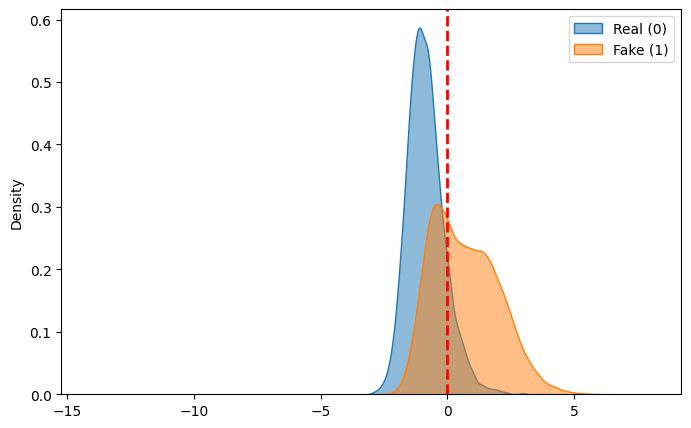

In [41]:
rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/5_experts_FULL_EVAL/A01-A03-A04_1000_pooled_real_from_validation"
scores, labels, attack_ids = load_results(rootpath)
show_ensemble(scores, labels)


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

    AUC%     EER%     Cllr   B.Acc.     Acc.    Prec.   Recall       F1
   84.45    23.77   1.7531    57.66    42.89    99.70    36.19    53.10

   Real mean score: -5.7542
   Fake mean score: -1.2763



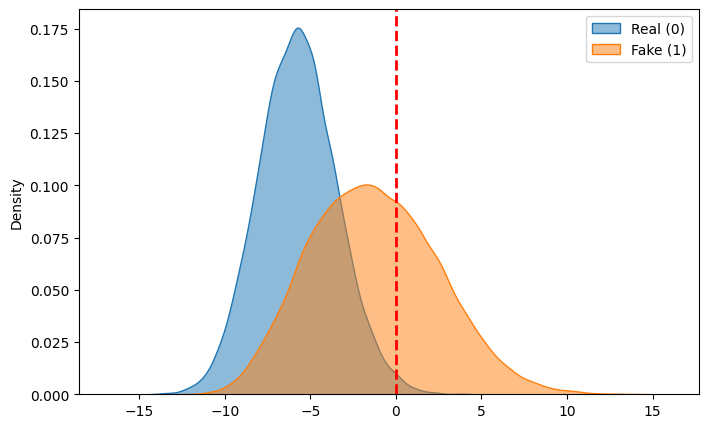

In [42]:
rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/5_experts_FULL_EVAL/A01-A03-A04_1000_real_from_validation"
scores, labels, attack_ids = load_results(rootpath)
show_ensemble(scores, labels)


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

    AUC%     EER%     Cllr   B.Acc.     Acc.    Prec.   Recall       F1
   78.14    28.42   1.4169    56.58    37.44    98.92    30.32    46.41

   Real mean score: -3.4135
   Fake mean score: -1.1307



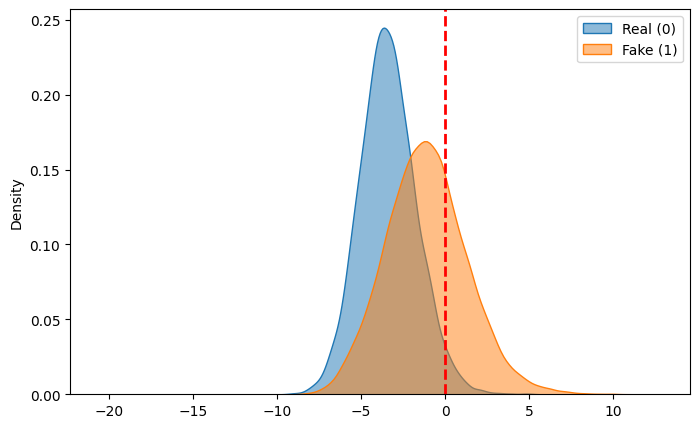

In [44]:
rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/5_experts_FULL_EVAL/ASVspoof2015_1000"
scores, labels, attack_ids = load_results(rootpath)
show_ensemble(scores, labels)


#--------- PER ATTACK, PER EXPERT ---------#



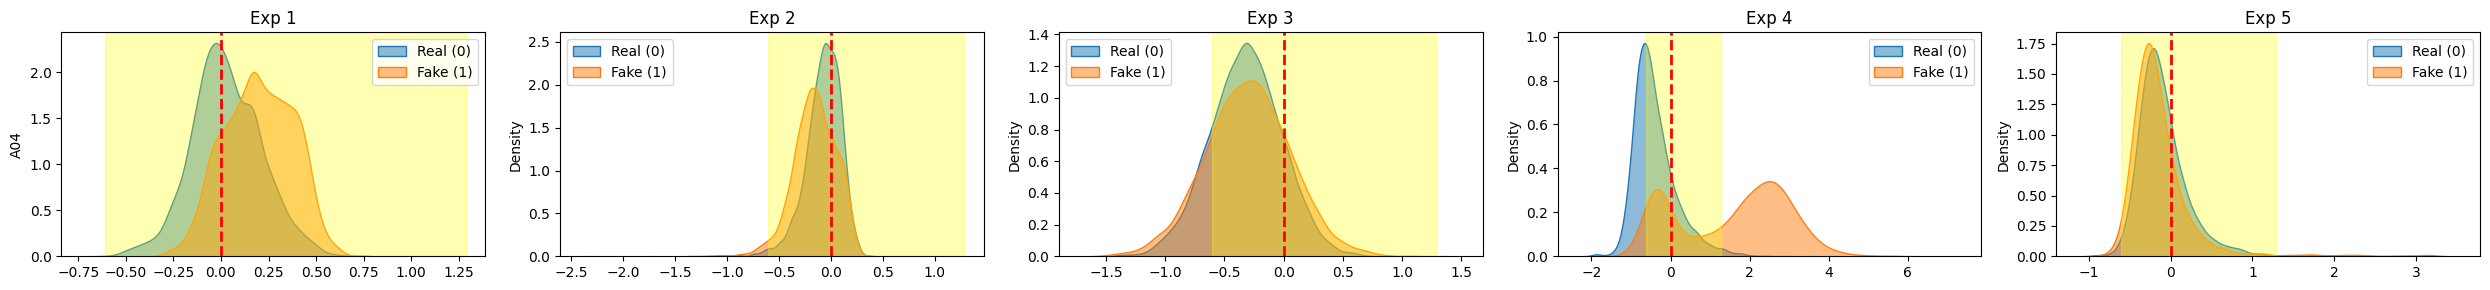

In [48]:
rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/5_experts_FULL_EVAL/A01-A03-A04_1000_pooled_real_from_validation"
scores, labels, attack_ids = load_results(rootpath)
selected_attacks = ['A04']
show_per_attack_per_expert(scores, labels, attack_ids, selected_attacks, show_metrics=False)


#--------- PER ATTACK, PER EXPERT ---------#



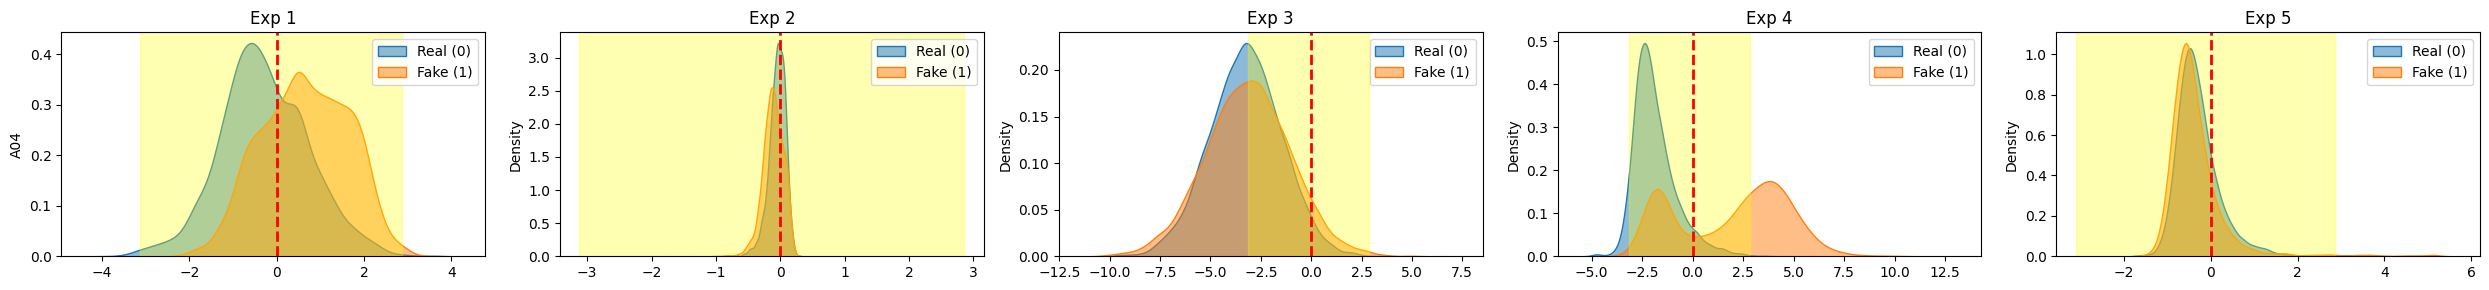

In [49]:
rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/5_experts_FULL_EVAL/A01-A03-A04_1000_real_from_validation"
scores, labels, attack_ids = load_results(rootpath)
selected_attacks = ['A04']
show_per_attack_per_expert(scores, labels, attack_ids, selected_attacks, show_metrics=False)


#--------- PER ATTACK, PER EXPERT ---------#



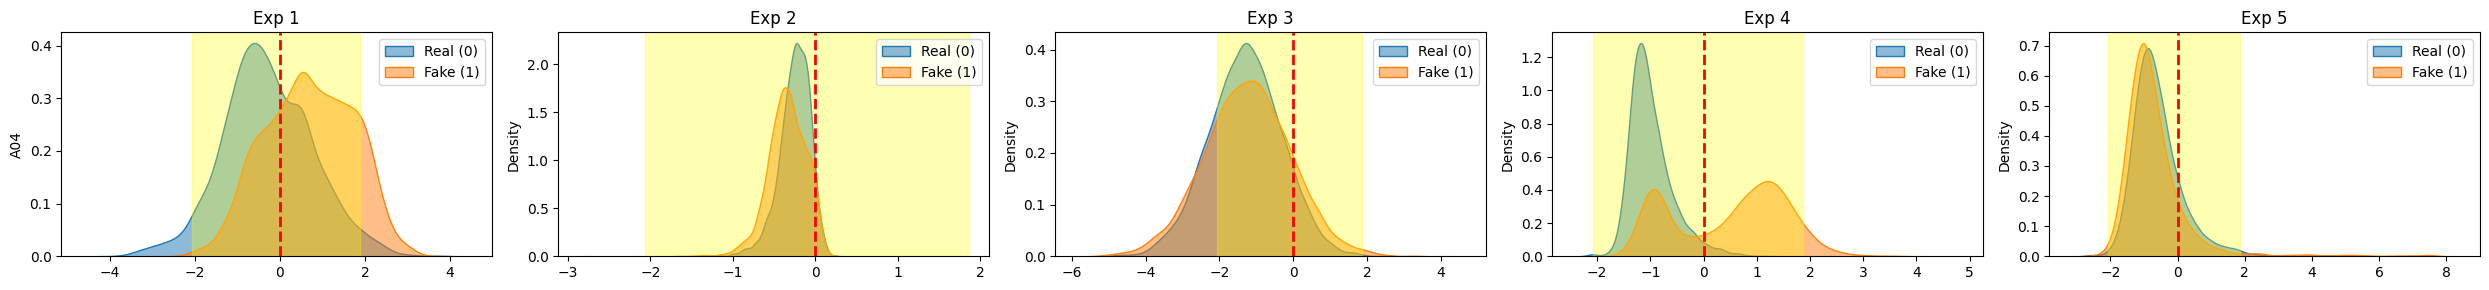

In [46]:
rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/5_experts_FULL_EVAL/ASVspoof2015_1000"
scores, labels, attack_ids = load_results(rootpath)
selected_attacks = ['A04']
show_per_attack_per_expert(scores, labels, attack_ids, selected_attacks, show_metrics=False)